# plot_tas_vs_pr — fractional aerosol variance, tas vs pr

Python port of `plot_tas_vs_pr.m`. Loads the precomputed regional response
ensembles for surface temperature (`tas`) and precipitation (`pr`) at three
regional resolutions:

* **regions1** — IPCC-WGI reference regions (58 regions),
* **regions2** — IPCC-WGII continental regions (8 regions),
* **regions3** — a fine 238-region grid.

For each region and timestep it computes the multi-model variance (sample
variance, `std(...,0)` → `ddof=1`) of the G6sulfur (`ta_reg_sulf`) and
G6solar (`ta_reg_solar`) responses, sums them to a total variance, and then
scatters the time-mean (years 41:81) fractional sulfur variance for tas
against pr.

The analysis is a faithful 1:1 translation; only the plotting back-end
(matplotlib) differs.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, brighten, movmean, ncread, shaperead, inpolygon, interp1, interp2

## regions1 — IPCC-WGI reference regions (58)
Per-region, per-timestep multi-model sample variance of the sulfur and solar
responses, then their sum.

In [2]:
m = mu.loadmat("tas_regions1.mat")
ta_reg_sulf = m["ta_reg_sulf"]          # (6, 81, 58)
ta_reg_solar = m["ta_reg_solar"]

regions = shaperead("IPCC-WGI-reference-regions-v4.shx")
nR1 = len(regions)                      # 58

tas_var1_sulf = np.full((nR1, 81), np.nan)
tas_var1_solar = np.full((nR1, 81), np.nan)
tot_var_reg1_tas = np.full((nR1, 81), np.nan)

for i in range(nR1):
    for t in range(81):
        x = ta_reg_sulf[:, t, i]
        y = ta_reg_solar[:, t, i]
        tas_var1_sulf[i, t] = np.std(x, ddof=1) ** 2
        tas_var1_solar[i, t] = np.std(y, ddof=1) ** 2
    tot_var_reg1_tas[i, :] = tas_var1_sulf[i, :] + tas_var1_solar[i, :]

## regions2 — IPCC-WGII continental regions (8)

In [3]:
regions = shaperead("IPCC_WGII_continental_regions.shx")

m = mu.loadmat("tas_regions2.mat")
ta_reg_sulf = m["ta_reg_sulf"]          # (6, 81, 8)
ta_reg_solar = m["ta_reg_solar"]

nR2 = len(regions)                      # 8

tas_var2_sulf = np.full((nR2, 81), np.nan)
tas_var2_solar = np.full((nR2, 81), np.nan)
tot_var_reg2_tas = np.full((nR2, 81), np.nan)

for i in range(nR2):
    for t in range(81):
        x = ta_reg_sulf[:, t, i]
        y = ta_reg_solar[:, t, i]
        tas_var2_sulf[i, t] = np.std(x, ddof=1) ** 2
        tas_var2_solar[i, t] = np.std(y, ddof=1) ** 2
    tot_var_reg2_tas[i, :] = tas_var2_sulf[i, :] + tas_var2_solar[i, :]

## regions3 — fine 238-region grid

In [4]:
m = mu.loadmat("tas_regions3.mat")
ta_reg_sulf = m["ta_reg_sulf"]          # (6, 81, 238)
ta_reg_solar = m["ta_reg_solar"]

tas_var3_sulf = np.full((238, 81), np.nan)
tas_var3_solar = np.full((238, 81), np.nan)
tot_var_reg3_tas = np.full((238, 81), np.nan)

for i in range(238):
    for t in range(81):
        x = ta_reg_sulf[:, t, i]
        y = ta_reg_solar[:, t, i]
        tas_var3_sulf[i, t] = np.std(x, ddof=1) ** 2
        tas_var3_solar[i, t] = np.std(y, ddof=1) ** 2
    tot_var_reg3_tas[i, :] = tas_var3_sulf[i, :] + tas_var3_solar[i, :]

## Precipitation — the same three resolutions
The `.mat` files reuse the variable names `ta_reg_sulf` / `ta_reg_solar`.

In [5]:
m = mu.loadmat("pr_regions1.mat")
ta_reg_sulf = m["ta_reg_sulf"]
ta_reg_solar = m["ta_reg_solar"]

regions = shaperead("IPCC-WGI-reference-regions-v4.shx")
nR1 = len(regions)

pr_var1_sulf = np.full((nR1, 81), np.nan)
pr_var1_solar = np.full((nR1, 81), np.nan)
tot_var_reg1_pr = np.full((nR1, 81), np.nan)

for i in range(nR1):
    for t in range(81):
        x = ta_reg_sulf[:, t, i]
        y = ta_reg_solar[:, t, i]
        pr_var1_sulf[i, t] = np.std(x, ddof=1) ** 2
        pr_var1_solar[i, t] = np.std(y, ddof=1) ** 2
    tot_var_reg1_pr[i, :] = pr_var1_sulf[i, :] + pr_var1_solar[i, :]

In [6]:
m = mu.loadmat("pr_regions2.mat")
ta_reg_sulf = m["ta_reg_sulf"]
ta_reg_solar = m["ta_reg_solar"]

regions = shaperead("IPCC_WGII_continental_regions.shx")
nR2 = len(regions)

pr_var2_sulf = np.full((nR2, 81), np.nan)
pr_var2_solar = np.full((nR2, 81), np.nan)
tot_var_reg2_pr = np.full((nR2, 81), np.nan)

for i in range(nR2):
    for t in range(81):
        x = ta_reg_sulf[:, t, i]
        y = ta_reg_solar[:, t, i]
        pr_var2_sulf[i, t] = np.std(x, ddof=1) ** 2
        pr_var2_solar[i, t] = np.std(y, ddof=1) ** 2
    tot_var_reg2_pr[i, :] = pr_var2_sulf[i, :] + pr_var2_solar[i, :]

In [7]:
m = mu.loadmat("pr_regions3.mat")
ta_reg_sulf = m["ta_reg_sulf"]
ta_reg_solar = m["ta_reg_solar"]

pr_var3_sulf = np.full((238, 81), np.nan)
pr_var3_solar = np.full((238, 81), np.nan)
tot_var_reg3_pr = np.full((238, 81), np.nan)

for i in range(238):
    for t in range(81):
        x = ta_reg_sulf[:, t, i]
        y = ta_reg_solar[:, t, i]
        pr_var3_sulf[i, t] = np.std(x, ddof=1) ** 2
        pr_var3_solar[i, t] = np.std(y, ddof=1) ** 2
    tot_var_reg3_pr[i, :] = pr_var3_sulf[i, :] + pr_var3_solar[i, :]

## Fractional sulfur variances and the scatter
Per-region fractional sulfur variance (%) at each timestep, then the time
mean over MATLAB columns 41:81 (`[40:81]`). Black = WGII (8 regions),
red = WGI (58 regions), blue = fine 238-region grid.

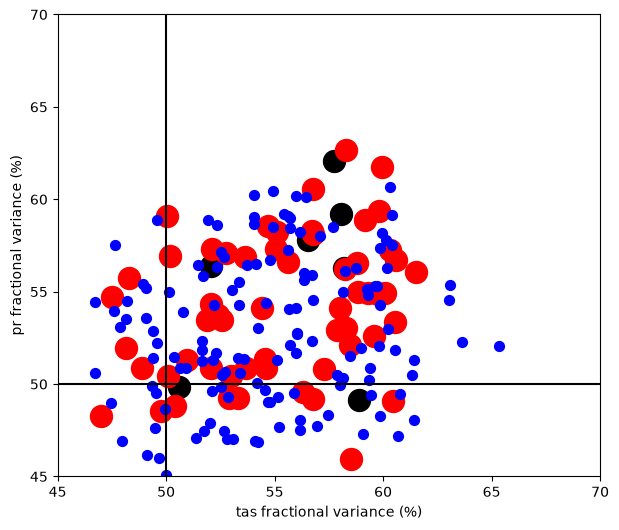

In [8]:
pr3 = pr_var3_sulf / tot_var_reg3_pr * 100
tas3 = tas_var3_sulf / tot_var_reg3_tas * 100

pr2 = pr_var2_sulf / tot_var_reg2_pr * 100
tas2 = tas_var2_sulf / tot_var_reg2_tas * 100

pr1 = pr_var1_sulf / tot_var_reg1_pr * 100
tas1 = tas_var1_sulf / tot_var_reg1_tas * 100

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(tas2[:, 40:81].mean(axis=1), pr2[:, 40:81].mean(axis=1),
           s=250, c="k")
ax.axis([45, 70, 45, 70])
ax.scatter(tas1[:, 40:81].mean(axis=1), pr1[:, 40:81].mean(axis=1),
           s=250, c="r")
ax.scatter(tas3[:, 40:81].mean(axis=1), pr3[:, 40:81].mean(axis=1),
           s=50, c="b")
ax.plot([50, 50], [0, 100], "k")
ax.plot([0, 100], [50, 50], "k")
ax.set_xlabel("tas fractional variance (%)")
ax.set_ylabel("pr fractional variance (%)")
fig.set_facecolor("w")
ax.set_facecolor("w")
plt.show()